In [29]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
from tqdm import tqdm

In [30]:
# 加载数据
data_df = pd.read_excel("/Users/luchi/Desktop/工作簿1.xlsx")
data_df.replace(r'^\s*$', np.nan, regex=True, inplace=True)
data_df.dropna(inplace=True)
data_df.reset_index(drop=True, inplace=True)

In [31]:
# 选择目标列
X = data_df.drop(columns=['Ug', 'Temp']).values
y = data_df[['Ug', 'Temp']].values  # ✅ 先定义 y

# 对 X 做标准化
from sklearn.preprocessing import StandardScaler
x_scaler = StandardScaler()
X_normalized = x_scaler.fit_transform(X)
X_tensor = torch.tensor(X_normalized, dtype=torch.float32)

# ✅ 对 y 也做标准化
y_scaler = StandardScaler()
y_normalized = y_scaler.fit_transform(y)
y_tensor = torch.tensor(y_normalized, dtype=torch.float32)


In [32]:
# === 构造高阶特征（平方项 + 交叉项） ===
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
import xgboost as xgb

# 多项式扩展（2阶：包含平方和交叉项）
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X)

# 重新标准化特征
x_scaler = StandardScaler()
X_poly_scaled = x_scaler.fit_transform(X_poly)
X_tensor = torch.tensor(X_poly_scaled, dtype=torch.float32)

# 标签标准化保持不变
y_tensor = torch.tensor(y_normalized, dtype=torch.float32)

# === 并行训练 XGBoost 模型（以第一个目标 Ug 为例）===
X_train_np, X_val_np, y_train_np, y_val_np = train_test_split(X_poly_scaled, y[:, 0], test_size=0.2, random_state=42)

xgb_model = xgb.XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.05)
xgb_model.fit(X_train_np, y_train_np)

y_pred = xgb_model.predict(X_val_np)

# 输出 R2
from sklearn.metrics import r2_score, mean_squared_error
xgb_r2 = r2_score(y_val_np, y_pred)
xgb_mse = mean_squared_error(y_val_np, y_pred)
print(f"XGBoost on Ug: R2 = {xgb_r2:.4f}, MSE = {xgb_mse:.6f}")


XGBoost on Ug: R2 = 0.8912, MSE = 0.004283


XGBoost on Temp: R2 = 0.3142, MSE = 5036.323322


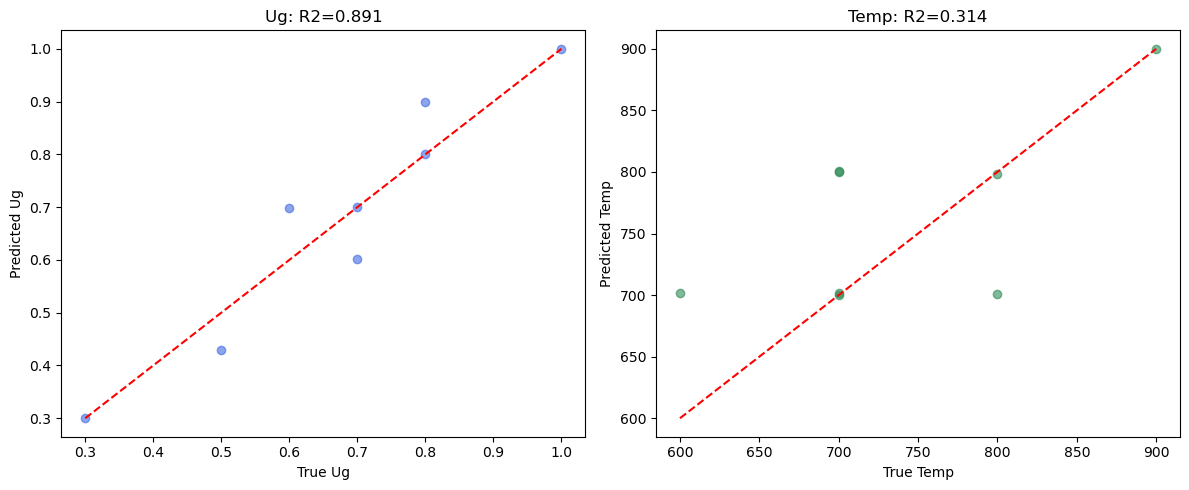

In [33]:
# === 对 Temp 目标训练 XGBoost ===
X_train_np2, X_val_np2, y_train_np2, y_val_np2 = train_test_split(X_poly_scaled, y[:, 1], test_size=0.2, random_state=42)

xgb_model2 = xgb.XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.05)
xgb_model2.fit(X_train_np2, y_train_np2)
y_pred2 = xgb_model2.predict(X_val_np2)

xgb_r2_2 = r2_score(y_val_np2, y_pred2)
xgb_mse_2 = mean_squared_error(y_val_np2, y_pred2)
print(f"XGBoost on Temp: R2 = {xgb_r2_2:.4f}, MSE = {xgb_mse_2:.6f}")

# === 可视化：真实值 vs 预测值 ===
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Ug 可视化
axs[0].scatter(y_val_np, y_pred, alpha=0.6, color='royalblue')
axs[0].plot([y_val_np.min(), y_val_np.max()], [y_val_np.min(), y_val_np.max()], 'r--')
axs[0].set_title(f"Ug: R2={xgb_r2:.3f}")
axs[0].set_xlabel("True Ug")
axs[0].set_ylabel("Predicted Ug")

# Temp 可视化
axs[1].scatter(y_val_np2, y_pred2, alpha=0.6, color='seagreen')
axs[1].plot([y_val_np2.min(), y_val_np2.max()], [y_val_np2.min(), y_val_np2.max()], 'r--')
axs[1].set_title(f"Temp: R2={xgb_r2_2:.3f}")
axs[1].set_xlabel("True Temp")
axs[1].set_ylabel("Predicted Temp")

plt.tight_layout()
plt.show()


In [34]:
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader

# 假设你已有 X_tensor, y_tensor
# 将数据按 80% 训练、20% 测试划分（随机）
X_train, X_test, y_train, y_test = train_test_split(
    X_tensor, y_tensor, test_size=0.2, random_state=42, shuffle=True
)

# 构造训练和测试集的 TensorDataset
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

# 加载器（batch_size = 64）
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)


In [35]:
data_df

,Level1,Level2,Level3,Level4,Level5,Level6,Level7,Level8,Level9,Level10,...,Level7_ratio,Level8_ratio,Level9_ratio,Level10_ratio,level11_ratio,level12_ratio,Average,StandardDeviation,Ug,Temp
0,7.095633,6.540241,9.440641,29.899873,242.556428,288.938382,75.362318,34.464444,12.212878,2.830087,...,0.105861,0.048412,0.017155,0.003975,0.002051,0.001538,2.122538,0.154313,0.1,600
1,7.164812,12.476508,21.225709,104.311549,552.463185,629.411474,254.385897,85.072098,21.802418,16.345294,...,0.143662,0.048044,0.012313,0.009231,0.012910,0.024399,2.327230,0.236246,0.2,600
2,7.705368,16.065269,32.305524,194.878763,756.871378,1054.011746,456.015510,103.022900,34.672851,24.312029,...,0.163037,0.036833,0.012396,0.008692,0.012739,0.029146,2.509746,0.296442,0.3,600
3,7.794771,19.146026,45.151540,236.663321,816.033055,1153.878788,637.924100,180.645079,42.396637,21.837303,...,0.199828,0.056587,0.013281,0.006840,0.003678,0.005999,2.694710,0.323635,0.4,600
4,7.905663,21.412906,54.154766,232.521722,841.428902,1372.609117,825.732932,139.814071,39.688321,13.670602,...,0.231946,0.039273,0.011148,0.003840,0.001322,0.001791,2.884014,0.343686,0.5,600
5,12.023154,21.165805,58.651988,250.987425,768.328807,1189.044638,820.490048,202.140441,62.761551,24.052545,...,0.238834,0.058840,0.018269,0.007001,0.003258,0.004240,3.012853,0.335825,0.6,600
6,13.609203,21.727860,64.548614,230.602446,732.059968,1397.939260,921.911173,215.776222,85.024399,53.986645,...,0.242935,0.056860,0.022405,0.014226,0.004155,0.011052,3.231901,0.351084,0.7,600
7,12.043687,21.795595,64.197187,217.289502,643.987461,1395.541437,912.126870,187.831040,93.618431,74.510265,...,0.243264,0.050094,0.024968,0.019872,0.012162,0.021602,3.536806,0.345781,0.8,600
8,11.486734,20.208289,60.435712,190.263832,516.503349,1318.914432,856.685695,191.343249,162.283263,62.355881,...,0.249251,0.055671,0.047216,0.018142,0.011017,0.002529,3.796007,0.337524,0.9,600
9,10.678404,18.545920,57.682131,184.951826,454.633839,957.424724,772.501625,203.289593,150.978913,127.175026,...,0.253766,0.066781,0.049596,0.041777,0.016762,0.018152,4.076703,0.311922,1.0,600


In [36]:
import torch
import torch.nn as nn

class ResidualBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.linear = nn.Linear(dim, dim)
        self.bn = nn.BatchNorm1d(dim)
        self.relu = nn.ReLU()

    def forward(self, x):
        return x + self.relu(self.bn(self.linear(x)))

class AdjustedRegressionModel(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.input_layer = nn.Linear(input_dim, 256)
        self.res1 = ResidualBlock(256)
        self.res2 = ResidualBlock(256)
        self.res3 = ResidualBlock(256)
        self.dropout = nn.Dropout(p=0.1)
        self.output_layer = nn.Linear(256, 2)

    def forward(self, x):
        x = self.input_layer(x)
        x = self.res1(x)
        x = self.dropout(x)
        x = self.res2(x)
        x = self.dropout(x)
        x = self.res3(x)
        x = self.output_layer(x)
        return x


In [37]:
# Define the number of splits for K-Fold cross-validation
n_splits = 5  # 可调整为更大以稳定评估  # 可调整为更大以稳定评估
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

# 调整优化参数
learning_rate = 3e-4  # 更小学习率通常带来更稳定训练
weight_decay = 1e-6
batch_size = 128
num_epochs = 500
patience, trials = 80, 25

# ===== 超参数设置 =====
learning_rate = 1e-4
weight_decay = 1e-6
batch_size = 256
num_epochs = 800
patience, trials = 100, 30
clip_grad_norm = 0.3

# ===== 超参数设置（更激进） =====
learning_rate = 3e-4
weight_decay = 1e-6
batch_size = 128
num_epochs = 700
patience, trials = 100, 30
clip_grad_norm = 0.3

# ===== 稳健参数配置，目标 R² > 0.9 =====
learning_rate = 5e-4
weight_decay = 1e-5
batch_size = 64
num_epochs = 1000
patience, trials = 200, 50
clip_grad_norm = 1.0

cv_results = {
    'train_loss': [],
    'val_loss': [],
    'val_r2': [],
    'val_mse': []
}


In [38]:
# 进度条
total_combinations = n_splits

with tqdm(total=total_combinations) as pbar:
    # Cross-validation loop
    for fold, (train_index, val_index) in enumerate(kf.split(X_tensor.numpy()), 1):
        print(f"FOLD {fold}")
        print("---------------------")

        # Split the data into current training and validation sets
        X_train = X_tensor[train_index]
        y_train = y_tensor[train_index]
        X_val = X_tensor[val_index]
        y_val = y_tensor[val_index]

        # Create data loaders for the current fold
        train_dataset = TensorDataset(X_train, y_train)
        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        val_dataset = TensorDataset(X_val, y_val)
        val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

        # Initialize the model for the current fold
        model = AdjustedRegressionModel(X_train.shape[1])
        criterion = nn.SmoothL1Loss()
        optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=10, factor=0.5, verbose=True)

        # Training with early stopping
        # 已在上方设定为更大轮数
        # 已在上方设定为更高早停容忍度
        best_val_loss = float('inf')
        train_losses = []  # 初始化训练损失列表

        # Training loop for the current fold
        for epoch in range(num_epochs):
            model.train()
            total_train_loss = 0
            for inputs, targets in train_loader:
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.5)  # Gradient clipping
                optimizer.step()
                total_train_loss += loss.item()
            train_losses.append(total_train_loss / len(train_loader))

            # Evaluate on the validation set for the current fold
            model.eval()
            total_val_loss = 0
            with torch.no_grad():
                for inputs, targets in val_loader:
                    outputs = model(inputs)
                    loss = criterion(outputs, targets)
                    total_val_loss += loss.item()

            # Calculate validation metrics for the current fold
            val_loss = total_val_loss / len(val_loader)
            val_predictions = torch.cat([model(inputs).detach() for inputs, _ in val_loader])

            # 由于输出是二元的，我们需要分别对每个输出计算R2和MSE，并计算平均值
            val_r2_es = r2_score(y_val.numpy()[:, 0], val_predictions.numpy()[:, 0])
            val_r2_cc0 = r2_score(y_val.numpy()[:, 1], val_predictions.numpy()[:, 1])
            val_r2 = (val_r2_es + val_r2_cc0) / 2  # 计算平均R2分数

            val_mse_es = mean_squared_error(y_val.numpy()[:, 0], val_predictions.numpy()[:, 0])
            val_mse_cc0 = mean_squared_error(y_val.numpy()[:, 1], val_predictions.numpy()[:, 1])
            val_mse = (val_mse_es + val_mse_cc0) / 2  # 计算平均MSE分数

            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_val_r2 = val_r2  # 记录最佳模型时的R2
                best_val_mse = val_mse  # 记录最佳模型时的MSE

                trials = 0
            else:
                trials += 1
                if trials >= patience:
                    print(f"Early stopping on fold {fold}, epoch {epoch}")
                    break

            scheduler.step(val_loss)  # 需要传入验证集损失

        # 在每个fold结束后记录指标
        print(f"Best validation loss for fold {fold}: {best_val_loss}")
        print(f"Best validation R2 for fold {fold}: {best_val_r2}")
        print(f"Best validation MSE for fold {fold}: {best_val_mse}")


  0%|          | 0/5 [00:00<?, ?it/s]/opt/anaconda3/envs/pytorch/lib/python3.9/site-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


FOLD 1
---------------------
Early stopping on fold 1, epoch 220
Best validation loss for fold 1: 0.07951507717370987
Best validation R2 for fold 1: 0.7123483121395111
Best validation MSE for fold 1: 0.15903016179800034
FOLD 2
---------------------


/opt/anaconda3/envs/pytorch/lib/python3.9/site-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Early stopping on fold 2, epoch 222
Best validation loss for fold 2: 0.18595579266548157
Best validation R2 for fold 2: 0.7134987413883209
Best validation MSE for fold 2: 0.3924490958452225
FOLD 3
---------------------


/opt/anaconda3/envs/pytorch/lib/python3.9/site-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Early stopping on fold 3, epoch 200
Best validation loss for fold 3: 0.2049122005701065
Best validation R2 for fold 3: 0.5294128060340881
Best validation MSE for fold 3: 0.4254674017429352
FOLD 4
---------------------


/opt/anaconda3/envs/pytorch/lib/python3.9/site-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Early stopping on fold 4, epoch 239
Best validation loss for fold 4: 0.21032603085041046
Best validation R2 for fold 4: 0.5499759912490845
Best validation MSE for fold 4: 0.5171696031466126
FOLD 5
---------------------


/opt/anaconda3/envs/pytorch/lib/python3.9/site-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(
  0%|          | 0/5 [00:06<?, ?it/s]

Early stopping on fold 5, epoch 238
Best validation loss for fold 5: 0.04348506033420563
Best validation R2 for fold 5: 0.8618415892124176
Best validation MSE for fold 5: 0.08697011834010482


In [39]:
import pandas as pd

# 确保模型处于评估模式
model.eval()

# === 对训练集预测 ===
with torch.no_grad():
    y_train_pred = model(X_train).cpu().numpy()
    y_val_pred = model(X_val).cpu().numpy()

# === 反标准化（还原到原始单位） ===
y_train_true = y_scaler.inverse_transform(y_train.cpu().numpy())
y_val_true = y_scaler.inverse_transform(y_val.cpu().numpy())
y_train_pred = y_scaler.inverse_transform(y_train_pred)
y_val_pred = y_scaler.inverse_transform(y_val_pred)

# === 构建训练集结果表格 ===
df_train = pd.DataFrame({
    "True_Ug_train": y_train_true[:, 0],
    "Pred_Ug_train": y_train_pred[:, 0],
    "True_Temp_train": y_train_true[:, 1],
    "Pred_Temp_train": y_train_pred[:, 1]
})

# === 构建验证集结果表格 ===
df_val = pd.DataFrame({
    "True_Ug_val": y_val_true[:, 0],
    "Pred_Ug_val": y_val_pred[:, 0],
    "True_Temp_val": y_val_true[:, 1],
    "Pred_Temp_val": y_val_pred[:, 1]
})

# === 保存为 CSV 文件 ===
df_train.to_csv("train_predictions.csv", index=False)
df_val.to_csv("val_predictions.csv", index=False)

print("✅ 训练集和验证集预测结果已保存：train_predictions.csv 和 val_predictions.csv")


✅ 训练集和验证集预测结果已保存：train_predictions.csv 和 val_predictions.csv


/var/folders/wy/490fn2dj4rngx0lns8t4g0fc0000gn/T/ipykernel_23126/838578828.py:35: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/wy/490fn2dj4rngx0lns8t4g0fc0000gn/T/ipykernel_23126/838578828.py:35: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/wy/490fn2dj4rngx0lns8t4g0fc0000gn/T/ipykernel_23126/838578828.py:35: UserWarning: Glyph 20540 (\N{CJK UNIFIED IDEOGRAPH-503C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/wy/490fn2dj4rngx0lns8t4g0fc0000gn/T/ipykernel_23126/838578828.py:35: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/wy/490fn2dj4rngx0lns8t4g0fc0000gn/T/ipykernel_23126/838578828.py:35: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/wy/490fn2dj4

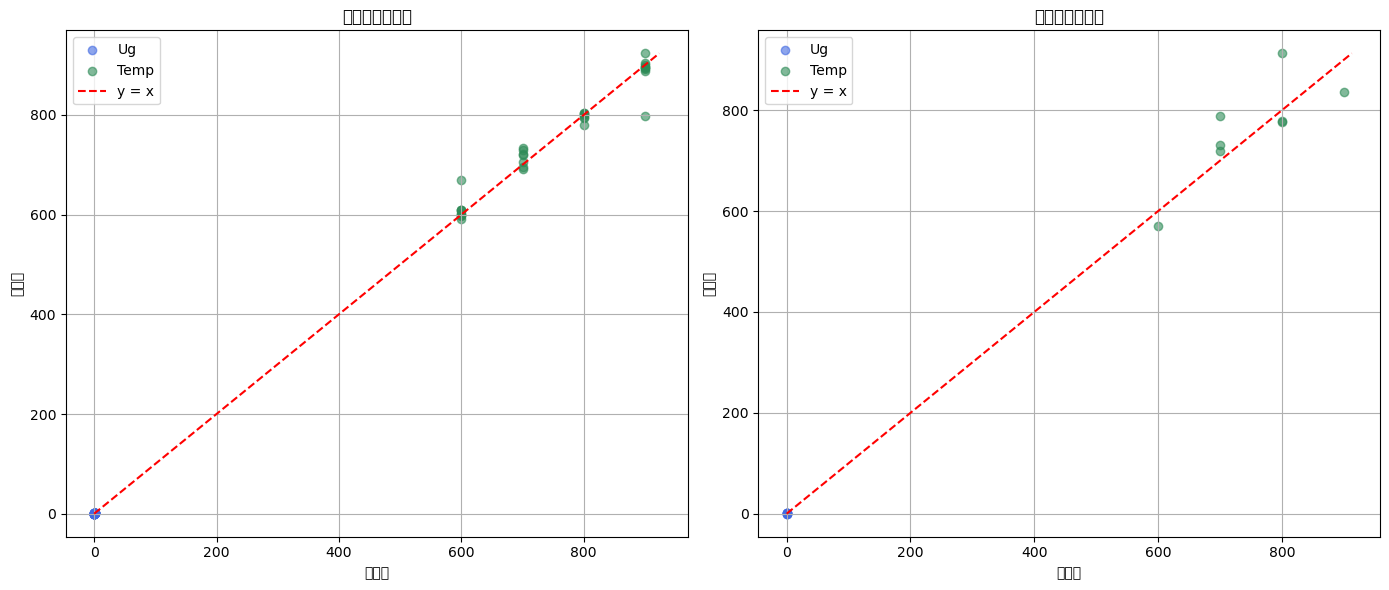

In [40]:
import pandas as pd
import matplotlib.pyplot as plt

# 读取 CSV 文件
df_train = pd.read_csv("train_predictions.csv")
df_val = pd.read_csv("val_predictions.csv")

# 创建图形
fig, axs = plt.subplots(1, 2, figsize=(14, 6))

# === 训练集绘图 ===
axs[0].scatter(df_train["True_Ug_train"], df_train["Pred_Ug_train"], alpha=0.6, label="Ug", color="royalblue")
axs[0].scatter(df_train["True_Temp_train"], df_train["Pred_Temp_train"], alpha=0.6, label="Temp", color="seagreen")
axs[0].plot([df_train.min().min(), df_train.max().max()],
            [df_train.min().min(), df_train.max().max()],
            'r--', label='y = x')
axs[0].set_title("训练集预测结果")
axs[0].set_xlabel("真实值")
axs[0].set_ylabel("预测值")
axs[0].legend()
axs[0].grid(True)

# === 验证集绘图 ===
axs[1].scatter(df_val["True_Ug_val"], df_val["Pred_Ug_val"], alpha=0.6, label="Ug", color="royalblue")
axs[1].scatter(df_val["True_Temp_val"], df_val["Pred_Temp_val"], alpha=0.6, label="Temp", color="seagreen")
axs[1].plot([df_val.min().min(), df_val.max().max()],
            [df_val.min().min(), df_val.max().max()],
            'r--', label='y = x')
axs[1].set_title("验证集预测结果")
axs[1].set_xlabel("真实值")
axs[1].set_ylabel("预测值")
axs[1].legend()
axs[1].grid(True)

plt.tight_layout()
plt.show()


/var/folders/wy/490fn2dj4rngx0lns8t4g0fc0000gn/T/ipykernel_23126/26122447.py:44: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/wy/490fn2dj4rngx0lns8t4g0fc0000gn/T/ipykernel_23126/26122447.py:44: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/wy/490fn2dj4rngx0lns8t4g0fc0000gn/T/ipykernel_23126/26122447.py:44: UserWarning: Glyph 20540 (\N{CJK UNIFIED IDEOGRAPH-503C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/wy/490fn2dj4rngx0lns8t4g0fc0000gn/T/ipykernel_23126/26122447.py:44: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/wy/490fn2dj4rngx0lns8t4g0fc0000gn/T/ipykernel_23126/26122447.py:44: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/wy/490fn2dj4rngx0

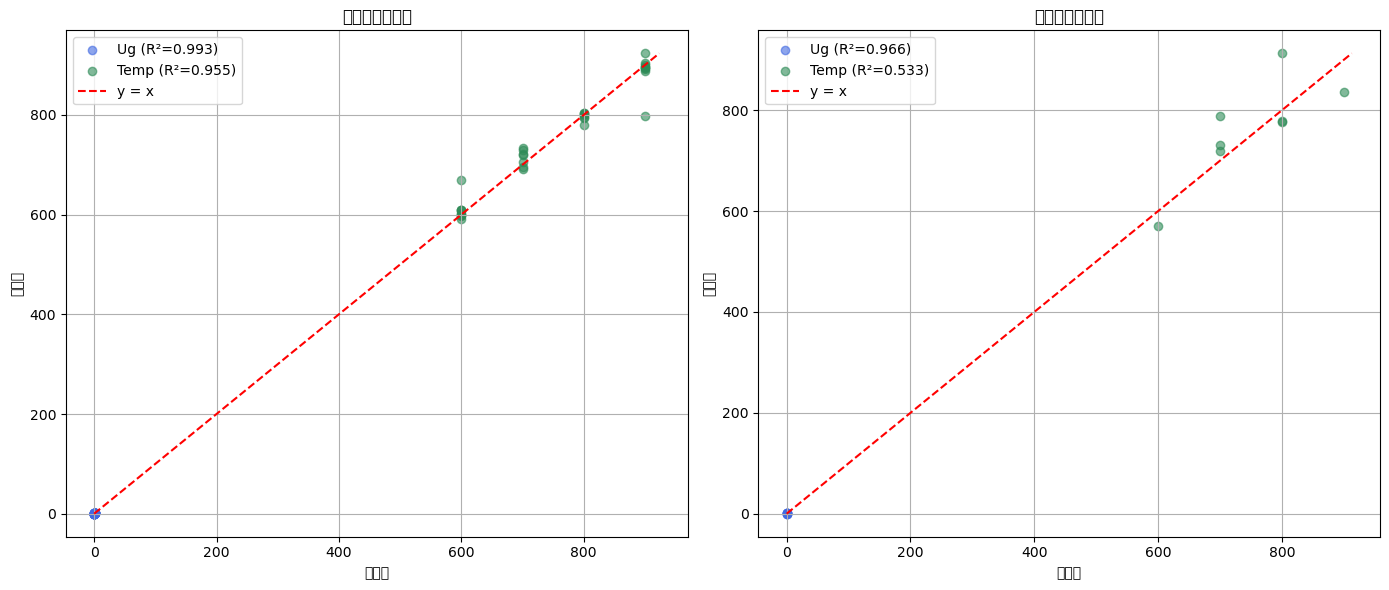

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

# 读取数据
df_train = pd.read_csv("train_predictions.csv")
df_val = pd.read_csv("val_predictions.csv")

# 计算 R²（训练集）
r2_train_ug = r2_score(df_train["True_Ug_train"], df_train["Pred_Ug_train"])
r2_train_temp = r2_score(df_train["True_Temp_train"], df_train["Pred_Temp_train"])

# 计算 R²（验证集）
r2_val_ug = r2_score(df_val["True_Ug_val"], df_val["Pred_Ug_val"])
r2_val_temp = r2_score(df_val["True_Temp_val"], df_val["Pred_Temp_val"])

# 创建图形
fig, axs = plt.subplots(1, 2, figsize=(14, 6))

# === 训练集绘图 ===
axs[0].scatter(df_train["True_Ug_train"], df_train["Pred_Ug_train"], alpha=0.6, label=f"Ug (R²={r2_train_ug:.3f})", color="royalblue")
axs[0].scatter(df_train["True_Temp_train"], df_train["Pred_Temp_train"], alpha=0.6, label=f"Temp (R²={r2_train_temp:.3f})", color="seagreen")
axs[0].plot([df_train.min().min(), df_train.max().max()],
            [df_train.min().min(), df_train.max().max()],
            'r--', label='y = x')
axs[0].set_title("训练集预测结果")
axs[0].set_xlabel("真实值")
axs[0].set_ylabel("预测值")
axs[0].legend()
axs[0].grid(True)

# === 验证集绘图 ===
axs[1].scatter(df_val["True_Ug_val"], df_val["Pred_Ug_val"], alpha=0.6, label=f"Ug (R²={r2_val_ug:.3f})", color="royalblue")
axs[1].scatter(df_val["True_Temp_val"], df_val["Pred_Temp_val"], alpha=0.6, label=f"Temp (R²={r2_val_temp:.3f})", color="seagreen")
axs[1].plot([df_val.min().min(), df_val.max().max()],
            [df_val.min().min(), df_val.max().max()],
            'r--', label='y = x')
axs[1].set_title("验证集预测结果")
axs[1].set_xlabel("真实值")
axs[1].set_ylabel("预测值")
axs[1].legend()
axs[1].grid(True)

plt.tight_layout()
plt.show()


In [42]:


        cv_results['val_loss'].append(best_val_loss)
        cv_results['train_loss'].append(train_losses)
        cv_results['val_r2'].append(best_val_r2)
        cv_results['val_mse'].append(best_val_mse)

        pbar.update(1)  # 更新进度条

# 寻找最佳组合
best_index = np.argmax(cv_results['val_r2'])
best_val_r2 = cv_results['val_r2'][best_index]

# 打印最终的交叉验证结果
print("Cross-validation results:")
print(f"Validation Loss: {cv_results['val_loss']}")
print(f"Validation R2: {cv_results['val_r2']}")
print(f"Validation MSE: {cv_results['val_mse']}")
print(f"Best parameter combination: (learning_rate, weight_decay, batch_size) with R2: {best_val_r2}")

Cross-validation results:
Validation Loss: [0.04348506033420563]
Validation R2: [0.8618415892124176]
Validation MSE: [0.08697011834010482]
Best parameter combination: (learning_rate, weight_decay, batch_size) with R2: 0.8618415892124176
